<img style="float: right; height: 120px; margin: 20px 0 10px 20px;" src="attachment:euclid_logo.png" alt="Euclid Consortium logo" />
<img style="float: right; height: 100px; margin: 30px 0 10px 20px;" src="attachment:ELSAlogo.png" alt="ELSA logo" />


# Galaxy physical properties at a chosen redshift from Euclid DR1

<br>

Copyright (c) Micol Bolzonella, Andrea Enia, Will Hartley, Giulia Papini, 2026.

This file is subject to the terms and conditions defined in file `LICENSE.txt`, which is part of this source code package. No part of the package, including this file, may be copied, modified, propagated, or distributed except according to the terms contained in the file `LICENSE.txt`.

**Last modified:** 2026-10-31

**Notebook summary**

The Euclid DR1 catalogues provide, for each galaxy, a photometric redshift and a set of physical properties (PPs): stellar mass, star-formation rate (SFR), dust attenuation, ages, rest-frame absolute magnitudes. These PPs are estimated from the photometry alone, treating the redshift as unknown. When a better redshift is available for a galaxy, for example a spectroscopic redshift, the PPs can be re-evaluated **at that redshift** using information already stored in the catalogue, without redoing any fit. We call the new redshift **zr**, since it can come from any source.

In this tutorial you will learn how to:

1. Understand how the PPs at a new redshift are derived, and what is needed to do it (Sections 1 and 2)
2. Retrieve a set of spectroscopic redshifts and the catalogue of PPs for one sky tile with ADQL queries (Section 3)
3. Check the distribution of the weights of the nearest neighbours (Section 4)
4. Derive the PPs at the new redshifts (Section 5)
5. Inspect the results with diagnostic plots (Section 6)

A companion notebook, `PP_at_z_companion.ipynb`, shows how to retrieve the PHZ catalogue for a list of objects and compares spectroscopic and photometric redshifts; it also lists the archive tables and the content of the reference sample.

**Glossary**

| Term | Meaning |
|---|---|
| PHZ | The Euclid processing function that produces photometric redshifts, object classification and galaxy physical properties |
| NNPZ | Nearest-Neighbour Photometric Redshifts: the machine-learning algorithm used by PHZ, which compares each galaxy with similar galaxies of known properties |
| MER | The Euclid processing function that produces the merged multi-band photometric catalogues (Euclid and ground-based bands) |
| SPE | The Euclid processing function that measures spectroscopic redshifts from the Euclid near-infrared slitless spectra |
| PP | Physical property of a galaxy (stellar mass, SFR, ...) |
| PDF | Probability distribution function |
| EWS, EDF, EAF | Euclid Wide Survey; Euclid Deep Fields (EDF-N, EDF-F, EDF-S); Euclid Auxiliary Fields (e.g. COSMOS) |
| Tile | Sky area unit of the Euclid catalogues; `tile_index` starts with 101 for Deep tiles and 102 for Wide tiles |
| ADQL | Astronomical Data Query Language, the SQL-like language used to query the Euclid archive |
| zr | The redshift at which the PPs are re-evaluated (spectroscopic, from another code, or any value) |

**Useful links:**

* [Euclid archive help pages: catalogues](https://euclid.dataspace.esa.int/community/help-pages/Catalogues.html)
* [Euclid DR1 homepage](https://www.cosmos.esa.int/web/euclid/euclid-dr1)
* [Euclid DR1 Data Product Description (Data Model)](https://euclid.esac.esa.int/dr/dr1/dpdd/)
* [Euclid Astroquery documentation](https://astroquery.readthedocs.io/en/latest/esa/euclid/euclid.html)

**References:**

* [E26] Enia et al. (2026), *Euclid Data Release 1: The PHZ processing function for the physical properties of galaxies*
* [H26] Hartley et al. (2026), *Euclid Data Release 1: Photo-z pipeline and validation*

**Running the notebook:**

* This notebook has **read-only permissions**. You can still run and edit cells, but to save your changes you have to save the notebook to a different location, for example your workspace.
* The functions used here are in the Python module **euclid_pp_tools.py** (v1.2), stored next to this notebook, except the three archive query functions, defined in the notebook. Each function is documented: type `help(function_name)` to read its description. You are welcome to copy the module to your workspace and modify it.
* The notebook is intended to be run with the **EUCLID-TOOLS kernel**, which includes all the necessary packages. It has been tested in the **IDR** archive environment.
* All the settings you normally need to change are in the **Configuration** cell below.


**Version:**

* v1.2: reference sample read from the DR1 calibration volume; explicit table names per survey; example restricted to one tile; functions moved to euclid_pp_tools.py, except the archive query functions; single login with automatic re-login if it expires; comparison of zr with the photometric redshifts; table names and selections set in the Configuration cell; additional queries moved to a companion notebook; method description revised.
* v1.1 (for ESA validation before DR1 release): method description and input requirements added; multiple redshifts per object fully supported; diagnostic plots selected automatically.
* v0.2: preliminary version sent to beta testers.

***

In [1]:
import io
import os
import re
import sys
import time
import getpass
import logging
import contextlib

import numpy as np
from astroquery import log as aq_log
from astroquery.esa.euclid.core import EuclidClass
from IPython.display import display

## Configuration

All the settings are here: paths, archive environment, table names and the selection of the example sample. The survey choice sets both the archive tables and the reference sample used in the computation, which must match.

In [2]:
# Folder containing euclid_pp_tools.py
shared_utilities_path = "/media/team_workspaces/EDS-user-group/Jupyter_Notebooks/DR1/PP_at_z/"

# Folder in your workspace for the output files
output_folder = "/media/user/example_notebook_outputs/"

# Archive environment and schema of the catalogue tables
env = "PDR"
SCHEMA = "dr1"

# Survey: 'DEEP' or 'WIDE'
SURVEY = "DEEP" 

# Example selection: one tile (101... = Deep, 102... = Wide)
TILE_INDEX = 101834632       # E.g. 101834632, 102015162
H_MAX = 23.5                 # H-band magnitude limit (AB)
SPE_PROB_MIN = 0.1           # minimum probability of the SPE redshifts
SPE_RANKS = (0, 1)           # SPE solutions to keep: (0,) for the best solution only
SPE_NDITH_MIN = 15           # minimum median number of dithers of the spectra: the Deep fields
                             # have many more visits than the Wide, use a value <= 4 for the Wide
                             # Example values: 3 for the Wide, 15 for the Deep
SPE_NPIX_MIN = 800           # minimum number of valid pixels of the spectra
                             # Example values: 450 for the Wide, 800 for the Deep

# Table names for each survey (without the schema)
TABLE_NAMES = {
    "DEEP": {"mer":         "mer_catalogue_deep_survey",
             "pp":          "phz_physical_parameters_deep_survey",
             "spe":         "spectro_z_spe_galaxy_candidates_deep",
             "spe_quality": "spectro_z_spe_quality_deep"},
    "WIDE": {"mer":         "mer_catalogue_wide_survey",
             "pp":          "phz_physical_parameters_wide",
             "spe":         "spectro_z_spe_galaxy_candidates_wide_survey",
             "spe_quality": "spectro_z_spe_quality_wide_survey"},
}

# --- Derived settings (no need to edit) ---
tables = {key: f"{SCHEMA}.{name}" for key, name in TABLE_NAMES[SURVEY].items()}
flux_h_min = 10 ** ((23.9 - H_MAX) / 2.5)   # MER fluxes are in microJy
os.makedirs(output_folder, exist_ok=True)

print(f"Survey: {SURVEY} | tile: {TILE_INDEX} | environment: {env} | outputs in: {output_folder}")
for key, name in tables.items():
    print(f"  {key:12s} -> {name}")

Survey: DEEP | tile: 101834632 | environment: PDR | outputs in: /media/user/example_notebook_outputs/
  mer          -> dr1.mer_catalogue_deep_survey
  pp           -> dr1.phz_physical_parameters_deep_survey
  spe          -> dr1.spectro_z_spe_galaxy_candidates_deep
  spe_quality  -> dr1.spectro_z_spe_quality_deep


In [3]:
if shared_utilities_path not in sys.path:
    sys.path.append(shared_utilities_path)

from euclid_pp_tools import (fix_nn_columns, merge_catalogs, read_catalog, write_catalog,
                             first_entry_per_object, run_nnpz_evaluation, load_reference_sample,
                             plot_weight_distribution, plot_zr_vs_zphot, pick_example, plot_neighbor_redshifts,
                             corner_for_object)

## Logging in

Log in **once**. For security reasons the login expires after a while: the query functions defined below detect this case (HTTP 401 / 403 errors), log in again automatically with `relogin` and repeat the query once; any other error is shown as it is. To log in again by hand, re-run this cell. Other login options are described in the [Euclid.login](https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass.login) documentation.

In [4]:
Euclid = EuclidClass(environment=env)

user = input("Enter your user name: ")  # Alternatively, set your user name here: user = ''
password = getpass.getpass(prompt="Enter your password: ")
Euclid.login(user=user, password=password, verbose=False)

relogin = lambda: Euclid.login(user=user, password=password, verbose=False)    # used only if the login expires
QUERY_OPTIONS = dict(relogin=relogin)

Enter your user name:  pcruzgam
Enter your password:  ········


INFO: Login to Euclid TAP server: eas.esac.esa.int:443/tap-server/tap/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid data service: eas.esac.esa.int:443/sas-dd/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid cutout service: eas.esac.esa.int:443/sas-cutout/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]


## Archive query functions

The three functions used to query the archive are defined here (all the other functions are in `euclid_pp_tools.py`):

| Function | What it does |
|---|---|
| `get_query_results` | Launches an ADQL query on the archive, prints the runtime and returns the result as a table |
| `is_auth_error` | Tells whether an archive error is due to a missing or expired login |
| `call_with_relogin` | Calls an archive function; only if the login has expired, logs in again and retries once |

Type `help(function_name)` to read their full description.

In [5]:
def get_query_results(query, name='query', n_rows=3, relogin=None):
    """
    Launch an asynchronous ADQL query on the Euclid archive, print the runtime
    and display the first rows of the result.

    It requires the archive object `Euclid`, already logged in (see the login cell).
    A newline is added at the end of the query, so that a '--' comment on its last
    line cannot comment out what the archive appends to the query.

    Parameters
    ----------
    query : str
        The ADQL query.
    name : str, optional
        Name of the job as it will appear in the archive (default is 'query').
    n_rows : int, optional
        Number of rows to display; 0 to display none (default is 3).
    relogin : callable, optional
        Function without arguments that logs in again, used only if the login
        has expired (default is None: errors are never retried).

    Returns
    -------
    astropy.table.Table
        The result of the query.
    """
    start = time.time()
    job = call_with_relogin(Euclid.launch_job_async, query.rstrip() + '\n', verbose=False, name=name,
                            relogin=relogin)
    res = call_with_relogin(job.get_results, relogin=relogin)
    print(f'* Output table contains {len(res):,} rows')
    print(f'* Total runtime: {time.time() - start:3.1f} seconds')
    if n_rows:
        print(f'* Displaying first {n_rows} rows: ')
        display(res[0:n_rows])
    return res


# Texts of the archive errors that mean "not logged in / session expired". The last one is the
# message logged by Euclid.launch_job_async for an expired login: the archive gives no reason
# for the HTTP error, so the message ends with "HTTP error:" followed by nothing.
AUTH_ERROR_PATTERNS = (r'Error\s+40[13]\b', r'unauthori[sz]ed', r'not\s+authenticated', r'authentication',
                       r'not\s+logged', r'login\s+required', r'session\s+(has\s+)?expired',
                       r'credentials\s+expiration', r'HTTP\s+error:\s*$')


def is_auth_error(error):
    """
    Tell whether an archive error is due to a missing or expired login.

    Parameters
    ----------
    error : Exception or str
        Exception raised by an astroquery call, or the error message logged
        by astroquery.

    Returns
    -------
    bool
        True for HTTP 401 / 403 errors and for messages about authentication
        (see AUTH_ERROR_PATTERNS).
    """
    status = getattr(getattr(error, 'response', None), 'status_code', None)
    if status in (401, 403):
        return True
    return any(re.search(p, str(error), re.IGNORECASE | re.MULTILINE) for p in AUTH_ERROR_PATTERNS)


def call_with_relogin(func, *args, relogin=None, **kwargs):
    """
    Call an archive function; only if the login has expired, log in again and
    repeat the call once.

    The Euclid archive functions of astroquery do not always raise an exception
    when a request fails: some of them (e.g. launch_job_async) log the error and
    return None. Both cases are detected: errors raised, and errors logged by
    astroquery during the call. The long HTML error page that astroquery prints
    for an expired login is hidden.

    Parameters
    ----------
    func : callable
        The archive function to call, e.g. Euclid.launch_job_async or
        Euclid.load_table.
    *args, **kwargs
        Arguments passed to `func`.
    relogin : callable, optional
        Function without arguments that logs in again (the `relogin` defined in
        the login cell). If None, errors are never retried.

    Returns
    -------
    object
        Whatever `func` returns.

    Raises
    ------
    RuntimeError
        If the request fails for any other reason than an expired login, or if
        it still fails after logging in again.
    """
    for attempt in (1, 2):
        error, printed = None, io.StringIO()
        with aq_log.log_to_list() as records, contextlib.redirect_stdout(printed):
            try:
                result = func(*args, **kwargs)
            except Exception as err:
                result, error = None, err
        messages = [r.getMessage() for r in records if r.levelno >= logging.ERROR]
        if error is None and (result is not None or not messages):
            print(printed.getvalue(), end='')
            return result
        reason = error if error is not None else messages[-1]
        if attempt == 1 and relogin is not None and is_auth_error(reason):
            print('⚠️ The login has expired: logging in again and repeating the request...')
            relogin()
            continue
        print(printed.getvalue(), end='')
        text = str(reason)
        if len(text) > 800:
            text = f'{text[:300]} [...] {text[-400:]}'
        raise RuntimeError(f'The archive request failed: {text}')

Check that the tables set in the Configuration cell exist in the archive. If one is reported as missing, correct `TABLE_NAMES` (Section 4 of the companion notebook lists all the archive tables).

In [6]:
archive_names = {t.get_qualified_name() for t in
                 call_with_relogin(Euclid.load_tables, only_names=True, include_shared_tables=True, **QUERY_OPTIONS)}
missing = [name for name in tables.values() if name not in archive_names]
print("All the tables were found." if not missing else
      f"⚠️ Not found in the archive: {missing}. Check TABLE_NAMES in the Configuration cell.")

INFO: Retrieving tables... [astroquery.utils.tap.core]
INFO: Parsing tables... [astroquery.utils.tap.core]
INFO: Done. [astroquery.utils.tap.core]
All the tables were found.


## 1. How the physical properties at a new redshift are derived

**The reference sample.** NNPZ compares each galaxy with a *reference sample* of real galaxies observed by Euclid in the COSMOS field, one of the EAFs, and matched to the COSMOS2020 catalogue. The comparison uses the photometry of the MER catalogues. There are two reference samples: one for the EWS (about 375 000 galaxies with $H_\mathrm{E} < 24$) and one for the EDFs (about 630 000 galaxies, with no magnitude cut) [E26]. The properties attached to each reference galaxy are obtained in two steps [E26, H26]:

1. a redshift PDF is derived by fitting the COSMOS2020 multi-band photometry with the SED-fitting code Phosphoros;
2. 50 redshifts are drawn from this PDF, and at each of them a second Phosphoros fit with the redshift fixed, using stellar population synthesis models, gives the PPs and absolute magnitudes.

Each reference galaxy therefore carries exactly **50 realizations**, each made of a redshift and the PPs consistent with that redshift.

**What the catalogue stores.** For each target galaxy, NNPZ finds its **30 nearest neighbours** in the reference sample, i.e. the reference galaxies with the most similar colours and magnitudes. The PHZ physical-parameters catalogue stores:

* `phz_pdf_nn_id`: the ids of the 30 neighbours in the reference sample;
* `phz_pdf_nn_weight`: their weights, i.e. the likelihood $e^{-\chi^2/2}$ of the match between the photometry of the target and of the neighbour, multiplied by a weight assigned to each reference galaxy to reduce the imprint of the large-scale structures of the COSMOS field [H26];
* `phz_pdf_nn_scale`: the flux scaling between target and neighbour, chosen for each neighbour to maximise the likelihood of the match times a log-normal prior, and limited to ±1.5 mag [H26]. Quantities that depend on the luminosity are rescaled accordingly: $\log M_\star$, $\log \mathrm{SFR}$ and the log of the formed mass are shifted by $\log_{10}(\mathrm{scale})$, absolute magnitudes by $-2.5\log_{10}(\mathrm{scale})$.

Together, these columns describe a weighted set of 30 × 50 = 1500 realizations for each target, which represents its PDF **marginalised over redshift**. In the pipeline, the published median, 68% interval and mode of each PP (`phz_pp_median_*`, ...) are computed from a random weighted resample of these realizations, so they carry a small Monte Carlo noise; the mode is the most frequent value in that resample. `phys_param_flags = 0` indicates that at least one neighbour has a weight larger than $10^{-3}$ [E26].

**Re-evaluating at a new redshift zr.** The tool keeps only the realizations whose redshift lies within a window $|z - z_r| < \Delta z$ and whose weight is positive. The half-width $\Delta z$ starts at 0.01 and grows in steps of 0.01 until at least `zr_min_num` realizations are found, or until it reaches the maximum `zr_tol`. The weighted quantiles, the weighted average and the value of the highest-weight realization are then computed from the selected realizations.

**What this implies in practice.**

* zr must fall within the redshift range covered by the realizations of the neighbours. If it does not (typically when zr is far from the photometric redshift), no realization is found and the object is flagged as a failure (`wgt_warning = 2`).
* If the realizations compatible with zr belong only to neighbours with extremely small weights (`wgt_warning = 1`), the neighbours at that redshift match the photometry poorly: these results should be treated with caution.
* A larger `zr_tol` reduces the number of failures, but the resulting PPs then refer to a broader redshift interval: the final window is stored in the `zr_window` column and should be checked.
* The COSMOS field contains few bright galaxies at low redshift: solutions at $z < 0.2$ with $\log(M_\star/M_\odot) > 10$ are strongly disfavoured, and the luminosity-dependent PPs can be biased there [H26].
* The PPs at zr are computed from all the realizations in the window, without resampling: small differences from the catalogue values (about 0.01 in redshift and a few hundredths of dex in stellar mass) are therefore expected even when zr is close to the photometric redshift.

## 2. What you need

<div style="border:1px solid #888; padding:10px; border-radius:5px">

| Purpose | Table | Required columns |
|---|---|---|
| **Compute the PPs at zr** (Section 5) | PHZ physical-parameters catalogue | `object_id`, `phz_pdf_nn_id`, `phz_pdf_nn_weight`, `phz_pdf_nn_scale` |
| | Redshift table | `object_id` and a redshift column of any name (passed as `zr_col`); optionally other columns to copy into the output (`zr_extra_cols`) |
| | PHZ reference sample | read automatically by the tool, for the survey set in `SURVEY` |
| **Diagnostic plots** (Section 6) | PHZ physical-parameters catalogue | in addition, the original PPs to compare with, e.g. `phz_pp_median_redshift`, `phz_pp_median_stellarmass`, `phz_pp_median_sfr`, ... |

</div>

* The other columns retrieved in this notebook (photometry, quality flags) are only used to select the sample.
* The **redshift table can be any table** (FITS or Parquet file, or an in-memory Astropy Table): your own spectroscopic catalogue, photometric redshifts from another code, a grid of trial redshifts, ... It does not need to come from the archive, and it can contain a different number of objects than the PHZ table: the two are matched by `object_id`.
* **Multiple redshifts for the same object are allowed** (e.g. different spectroscopic solutions, or redshifts from different sources): the PPs are evaluated at each of them, so the output can contain the same `object_id` several times, once per redshift. Exact duplicates (same object and redshift) are processed once, and redshifts ≤ 0 are discarded.

A minimal query retrieving only what the computation needs is:

```sql
SELECT pp.object_id, pp.phz_pdf_nn_id, pp.phz_pdf_nn_weight, pp.phz_pdf_nn_scale
FROM catalogue.phz_physical_parameters_deep_survey AS pp
WHERE ...   -- your selection, e.g. on tile_index
```

If your redshifts are in a table of your own, you can upload its `object_id` column to the archive as a temporary table and join it in the query, to retrieve the PHZ columns of exactly those objects: Section 1 of the companion notebook `PP_at_z_companion.ipynb` shows how.

## 3. Retrieving the input data

The example uses the objects of a single tile, set by `TILE_INDEX` in the Configuration cell, to keep the queries fast. The same queries work for any tile, Deep or Wide, as long as `SURVEY` matches the tile; for a Wide tile, also lower `SPE_NDITH_MIN` and `SPE_NPIX_MIN`.

### 3.1 Redshifts: SPE spectroscopic redshifts

To show how the tool handles **several redshifts for the same object**, the query retrieves both the first and the second SPE solutions (`SPE_RANKS = (0, 1)`) with probability above `SPE_PROB_MIN = 0.1`. These are not all reliable redshifts: they are only an example. For the best solution with high probability only, set `SPE_RANKS = (0,)` and `SPE_PROB_MIN = 0.9999` in the Configuration cell.

In [7]:
ranks = ", ".join(str(r) for r in SPE_RANKS)

query = f"""SELECT mer.object_id, mer.right_ascension, mer.declination, mer.tile_index,
            spe.spe_z, spe.spe_z_err, spe.spe_z_prob, spe.spe_z_rel, spe.spe_rank,
            speq.spe_npix, speq.spe_n_dith_med
            FROM {tables['spe']} AS spe
            JOIN {tables['spe_quality']} AS speq
              ON spe.object_id = speq.object_id
            JOIN {tables['mer']} AS mer
              ON spe.object_id = mer.object_id
            WHERE mer.tile_index = {TILE_INDEX}
            AND mer.spurious_flag = 0
            AND spe.spe_z > 0
            AND spe.spe_z_prob >= {SPE_PROB_MIN}
            AND spe.spe_z_rel > 0.05
            AND spe.spe_rank IN ({ranks})
            AND speq.spe_n_dith_med >= {SPE_NDITH_MIN}
            AND speq.spe_npix >= {SPE_NPIX_MIN}
            """
spe_results_table = get_query_results(query, 'SPE-query', **QUERY_OPTIONS)

INFO: Query finished. [astroquery.utils.tap.core]
* Output table contains 2,546 rows
* Total runtime: 2.0 seconds
* Displaying first 3 rows: 


object_id,right_ascension,declination,tile_index,spe_z,spe_z_err,spe_z_prob,spe_z_rel,spe_rank,spe_npix,spe_n_dith_med
NA,deg,deg,,NA,NA,NA,NA,NA,NA,
int64,float64,float64,int64,float64,float64,float64,float64,int16,int16,int16
2700482552662990300,270.04825529764054,66.29903007394613,101834632,1.243080973625183,0.0007039993652142584,0.19982440769672394,0.06385517120361328,1,849,21
2700482552662990300,270.04825529764054,66.29903007394613,101834632,2.9489524364471436,0.0012572159757837653,0.787724494934082,0.06385517120361328,0,849,21
2698691390663326240,269.8691390204503,66.33262400163207,101834632,0.8633022904396057,0.0007031862623989582,0.9993916153907776,0.3328767716884613,0,847,21


The table is sorted by `object_id` and `spe_rank`. When an object has several redshifts, the output of the tool keeps the order of the input redshift table, and in Section 6 the **first redshift of each object** is used for the plots: sorting by `spe_rank` makes it the best SPE solution. The table is then saved with `write_catalog`, in FITS or Parquet format depending on the extension of the file name (`.fits` or `.parquet`). On later runs you can skip the query and read the file with `read_catalog(output_folder + spe_file)`, which also recognises the format from the extension.

In [8]:
spe_results_table.sort(['object_id', 'spe_rank'])

spe_file = 'example_spe.parquet'   # or .fits
write_catalog(spe_results_table, output_folder + spe_file)

✅ Successfully saved catalog to: /media/user/example_notebook_outputs/example_spe.parquet


### 3.2 PHZ physical-parameters catalogue

The query retrieves the three nearest-neighbour columns **required** by the tool, plus the original PPs, which are **optional** and only used in the plots of Section 6. The conditions on magnitude, size and point-like probability select extended galaxies brighter than `H_MAX`.

In [9]:
query = f"""SELECT mer.object_id, mer.right_ascension, mer.declination, mer.tile_index,
            mer.flux_h_sersic,
            -- required by the tool:
            pp.phz_pdf_nn_id, pp.phz_pdf_nn_scale, pp.phz_pdf_nn_weight,
            -- optional, used only in the plots:
            pp.phz_pp_median_redshift, pp.phz_pp_mode_redshift,
            pp.phz_pp_median_stellarmass, pp.phz_pp_median_sfr,
            pp.phz_pp_median_av, pp.phz_pp_median_sfhage,
            pp.quality_flag, pp.phys_param_flags
            FROM {tables['mer']} AS mer
            JOIN {tables['pp']} AS pp
              ON mer.object_id = pp.object_id
            WHERE mer.tile_index = {TILE_INDEX}
            AND mer.spurious_flag = 0
            AND mer.flux_h_sersic > {flux_h_min:.4f}
            AND mer.kron_radius < 50
            AND mer.point_like_prob < 0.05
            AND pp.phys_param_flags = 0
            """

pp_results_table = get_query_results(query, 'PP-query', **QUERY_OPTIONS)

INFO: Query finished. [astroquery.utils.tap.core]
* Output table contains 5,429 rows
* Total runtime: 8.8 seconds
* Displaying first 3 rows: 


object_id,right_ascension,declination,tile_index,flux_h_sersic,phz_pdf_nn_id,phz_pdf_nn_scale,phz_pdf_nn_weight,phz_pp_median_redshift,phz_pp_mode_redshift,phz_pp_median_stellarmass,phz_pp_median_sfr,phz_pp_median_av,phz_pp_median_sfhage,quality_flag,phys_param_flags
NA,deg,deg,,uJy,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
int64,float64,float64,int64,float64,float64[30],float64[30],float64[30],float64,float64,float64,float64,float64,float64,float64,float64
2696731244661291965,269.67312446708746,66.12919655093647,101834632,4.210155963897705,365162.0 .. 616828.0,0.7166287302970886 .. 0.45717406272888184,1.8974422033579685e-08 .. 2.903006190990709e-07,0.2619999945163727,0.25200000405311584,8.678606033325195,-1.0761539936065674,0.04977547749876976,9.905877113342285,0.0,0.0
2700296213661276297,270.0296213752645,66.1276297504519,101834632,13.927094459533691,499229.0 .. 623038.0,1.7151192426681519 .. 1.2953873872756958,1.747326147763326e-35 .. 1.6189341457579175e-20,0.7820000052452087,0.7739999890327454,10.17267894744873,1.0046337842941284,0.6067274808883667,4.222341537475586,0.0,0.0
2696164429661361708,269.6164429630641,66.13617085657206,101834632,4.673467636108398,164011.0 .. 627522.0,1.707665205001831 .. 3.0670664310455322,3.8997058078409086e-15 .. 1.729793837057514e-07,0.5139999985694885,0.5180000066757202,9.101334571838379,0.17894254624843597,0.65119868516922,2.149488925933838,0.0,0.0


Depending on the access route, the nearest-neighbour columns can be returned as strings: `fix_nn_columns` converts them to numeric arrays if needed. The table is then saved, again in the format given by the extension (read it back later with `read_catalog(output_folder + pp_file)`).

In [10]:
pp_results_table = fix_nn_columns(pp_results_table)

pp_file = 'example_pp.parquet'   # or .fits
write_catalog(pp_results_table, output_folder + pp_file)

phz_pdf_nn_id: numeric (int64, shape (30,))
phz_pdf_nn_weight: numeric (float64, shape (30,))
phz_pdf_nn_scale: numeric (float64, shape (30,))
✅ Successfully saved catalog to: /media/user/example_notebook_outputs/example_pp.parquet


## 4. Distribution of the NNPZ weights

The weights of the neighbours are likelihoods, so they span many orders of magnitude. This check gives an overview of the weights in your sample and helps interpreting the `wgt_warning` flag of the output: an object is flagged with `wgt_warning = 1` when the largest weight among the realizations selected around zr is below $10^{-30}$.

Total weights         : 162870
Weights = 0           : 6912
Minimum positive (> 0): 1.401298464324817e-45
Maximum weight        : 2.0708281993865967
0 < weight < 1e-30  : 6609


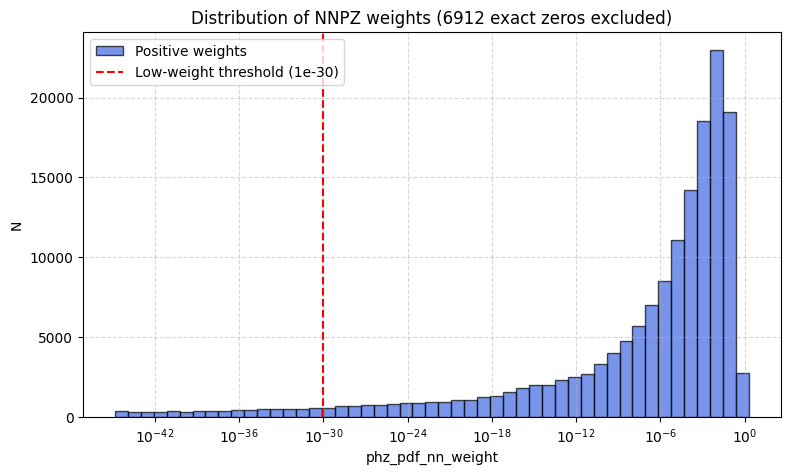

In [11]:
plot_weight_distribution(pp_results_table)

## 5. Physical properties at z = zr

`run_nnpz_evaluation` matches the PHZ catalogue and the redshift table by `object_id` and evaluates the requested PPs at each redshift (type `help(run_nnpz_evaluation)` for the full description). The main arguments are:

* `euclid_survey`: `'DEEP'` or `'WIDE'`, must match the PHZ catalogue (here set by `SURVEY`);
* `params`: list of PPs to evaluate, or `'all'`;
* `quantiles`: quantiles of the posterior to compute (0.5 is labelled `median`);
* `zr_col`: name of the redshift column in the redshift table;
* `zr_min_num`, `zr_tol`: minimum number of realizations and maximum half-width of the redshift window (see Section 1);
* `zr_extra_cols`: columns of the redshift table to copy into the output; here `spe_rank`, to keep track of which SPE solution each row refers to;
* `out_file`: output file, or `None` to keep the result only in memory. **The format depends on the extension**: `.fits` (or `.fit`) for FITS, `.parquet` for Parquet.

The function returns a table with **one row per (object, redshift) pair**, in the same order as the redshift table.

In [12]:
zr_file = 'PHZ_PP_zr_results_example.parquet'   # or .fits

tnew = run_nnpz_evaluation(
    nnpz_table    = pp_results_table,
    zr_table      = spe_results_table,
    euclid_survey = SURVEY,
    out_file      = output_folder + zr_file,
    params        = ['STELLARMASS', 'SFR', 'REDSHIFT', 'AV', 'SFHAGE'],   # or 'all'
    quantiles     = [0.16, 0.5, 0.84],
    zr_col        = 'spe_z',
    zr_min_num    = 5,
    zr_tol        = 0.3,
    zr_extra_cols = ['spe_rank'],
)

Using in-memory Astropy Table for the PHZ catalogue.
Number of PHZ entries: 5429
Using in-memory Astropy Table for the redshift catalogue.
Number of redshift entries: 2546
ℹ️ 293 objects have more than one redshift: the PPs will be evaluated at all of them.
Running analysis on 1726 matched (object, redshift) pairs with z > 0.
Loading DEEP reference sample from /data/euclid_dr1_cal/calproductsDR1/PHZ...
Processing on 127 cores...



Evaluating quantiles: 100%|██████████| Elapsed: 00:01 ETA: 00:00



Formatting results...

               PROCESSING SUMMARY
(object, z) pairs processed:     1726
Distinct objects:                1535
🟩 Clean (status 0):              1321 ( 76.5%)
⚠️ Low weight (status 1):          55 (  3.2%)
🔴 Failures, -99 (status 2):       350 ( 20.3%)
Mean NN_valid (status 0-1):      86.0
✅ Successfully saved catalog to: /media/user/example_notebook_outputs/PHZ_PP_zr_results_example.parquet
Total processing time: 3.74 seconds


**Output columns**

| Column | Description |
|---|---|
| `object_id` | object identifier |
| `spe_z` (the `zr_col`) | redshift at which the PPs are evaluated |
| `spe_rank` (the `zr_extra_cols`) | copied from the redshift table |
| `phz_pp_zr_16_<param>`, `phz_pp_zr_median_<param>`, `phz_pp_zr_84_<param>` | weighted quantiles of the PP at zr |
| `phz_pp_zr_avg_<param>` | weighted average |
| `phz_pp_zr_bestnn_<param>` | value of the highest-weight realization in the window |
| `NN_number` | number of realizations within the final redshift window (any weight) |
| `NN_valid` | number of realizations within the final window with weight > 0 (realizations, not neighbours: there are 50 per neighbour) |
| `zr_window` | final half-width of the redshift window |
| `wgt_warning` | 0 = clean; 1 = low weight (largest weight in the window < 1e-30); 2 = failure, no realization with weight > 0 within `zr_tol` (values set to -99); 3 = unexpected error while processing the object (values set to -99) |

**Units of the PPs** [E26]: `STELLARMASS` and `MASSFORMED` in $\log_{10}(M/M_\odot)$, `SFR` in $\log_{10}(\mathrm{SFR}/M_\odot\,\mathrm{yr}^{-1})$, `SFHAGE` and `SFHTIMESCALE` in Gyr, `STELLARMETALLICITY` in $Z/Z_\odot$, `AV` and absolute magnitudes in mag; Chabrier (2003) initial mass function. Luminosity-dependent quantities are already rescaled to the flux of the target.

The fraction of failures depends on how far the new redshifts are from the photometric ones: with the low-probability SPE solutions included in this example, it can be significant.

In [13]:
tnew[0:5]

object_id,spe_z,spe_rank,phz_pp_zr_16_stellarmass,phz_pp_zr_median_stellarmass,phz_pp_zr_84_stellarmass,phz_pp_zr_avg_stellarmass,phz_pp_zr_bestnn_stellarmass,phz_pp_zr_16_sfr,phz_pp_zr_median_sfr,phz_pp_zr_84_sfr,phz_pp_zr_avg_sfr,phz_pp_zr_bestnn_sfr,phz_pp_zr_16_redshift,phz_pp_zr_median_redshift,phz_pp_zr_84_redshift,phz_pp_zr_avg_redshift,phz_pp_zr_bestnn_redshift,phz_pp_zr_16_av,phz_pp_zr_median_av,phz_pp_zr_84_av,phz_pp_zr_avg_av,phz_pp_zr_bestnn_av,phz_pp_zr_16_sfhage,phz_pp_zr_median_sfhage,phz_pp_zr_84_sfhage,phz_pp_zr_avg_sfhage,phz_pp_zr_bestnn_sfhage,NN_number,NN_valid,zr_window,wgt_warning
NA,NA,NA,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
int64,float64,int16,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,int32,int32,float32,int16
2695183214663677443,1.483702301979065,0,9.309026,9.40724,9.45927,9.380222,9.317373,1.3851334,1.4018044,1.4345933,1.4064788,1.4020547,1.478,1.482,1.49024,1.4833333,1.492,0.3904636,0.41873798,0.46390465,0.42499733,0.46390465,0.10892443,0.17966425,0.20151624,0.1536363,0.10892443,148,148,0.01,0
2695188235663557514,1.4949041604995728,0,9.400206,9.586261,9.658103,9.548711,9.626717,1.3199632,1.3613493,1.434871,1.3797754,1.3744746,1.492,1.5,1.504,1.4978328,1.504,0.31022245,0.36947155,0.46223122,0.38853872,0.31029484,0.15608302,0.2586334,0.4922673,0.30654258,0.2067914,182,182,0.01,0
2695202456662993133,2.8983380794525146,0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,0,0,0.3,2
2695202456662993133,1.214552402496338,1,9.716051,9.766399,9.913237,9.81959,9.720917,1.2768403,1.5066966,1.6412455,1.4600792,1.5071722,1.212,1.218,1.2214236,1.2176399,1.22,0.685082,0.99617255,1.055298,0.9201001,1.055298,0.27664167,0.36281496,1.1529416,0.7637931,0.36281496,87,87,0.01,0
2695211858663083872,0.9725958108901978,0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,0,0,0.3,2


Objects with more than one redshift appear several times in the output, once per redshift. For example:

In [14]:
ids, counts = np.unique(tnew['object_id'], return_counts=True)
print(f"{np.sum(counts > 1)} of {len(ids)} objects have more than one redshift")

if np.any(counts > 1):
    example = tnew[tnew['object_id'] == ids[counts > 1][0]]
    print(example['object_id', 'spe_z', 'spe_rank', 'phz_pp_zr_median_stellarmass',
                  'phz_pp_zr_median_sfr', 'zr_window', 'wgt_warning'])

191 of 1535 objects have more than one redshift
     object_id            spe_z        spe_rank ... zr_window wgt_warning
         NA                 NA            NA    ...                      
------------------- ------------------ -------- ... --------- -----------
2695202456662993133 2.8983380794525146        0 ...       0.3           2
2695202456662993133  1.214552402496338        1 ...      0.01           0


## 6. Inspecting the results

### 6.1 New redshifts versus photometric redshifts

A first overall check: each new redshift zr compared with the photometric redshift of the PHZ catalogue (`phz_pp_median_redshift`), with one symbol per processing status. All the (object, redshift) pairs are shown, so objects with several redshifts appear more than once. The dotted lines mark $|z_r - z_\mathrm{phot}| = 0.15\,(1+z_r)$.

As explained in Section 1, failures (`wgt_warning = 2`) are expected where zr is far from the photometric redshift, since no neighbour has realizations at zr.

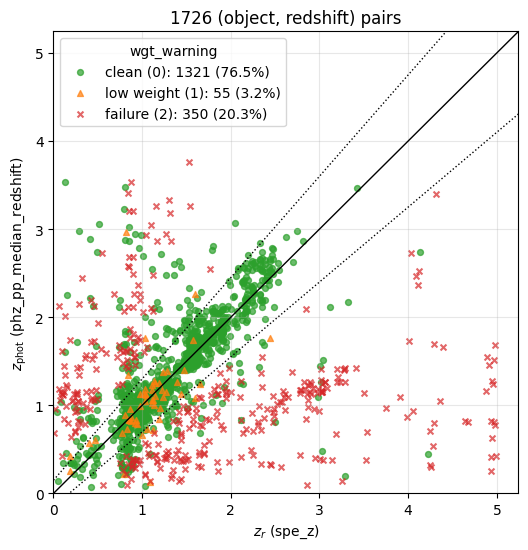

In [15]:
plot_zr_vs_zphot(tnew, pp_results_table, zr_col='spe_z', zp_col='phz_pp_median_redshift')

### 6.2 One redshift per object for the plots

`tnew` contains the PPs at **all** the redshifts provided. For the comparison plots we need a single entry per object, and we take the **first** one, i.e. the first redshift given for that object in the input table. Here this is the best SPE solution, because the redshift table was sorted by `spe_rank`. When redshifts come from different sources it is not always possible to rank them: it is then up to you to order the input table as preferred.

The selected entries are merged with the PHZ catalogue, which provides the original PPs for comparison.

In [16]:
tnew_first = first_entry_per_object(tnew)
merged_catalog = merge_catalogs(pp_results_table, tnew_first)
print(f"{len(tnew)} (object, redshift) pairs -> {len(merged_catalog)} objects in the merged catalogue")

1726 (object, redshift) pairs -> 1535 objects in the merged catalogue


### 6.3 Redshift distribution of the nearest neighbours

The plots show, for one object, the redshifts of all the realizations of its 30 neighbours (grey, unweighted, and blue, weighted), the new redshift zr, the original photometric redshift, and the window finally adopted around zr. They need the reference sample, which is loaded first. One example object is picked automatically for each processing status.

Loading DEEP reference sample from /data/euclid_dr1_cal/calproductsDR1/PHZ...
--- Example: clean (wgt_warning = 0) ---


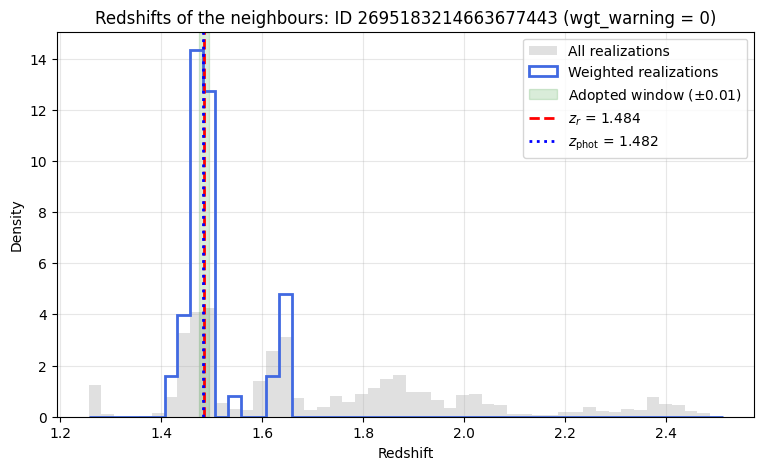

--- Example: low weight (wgt_warning = 1) ---


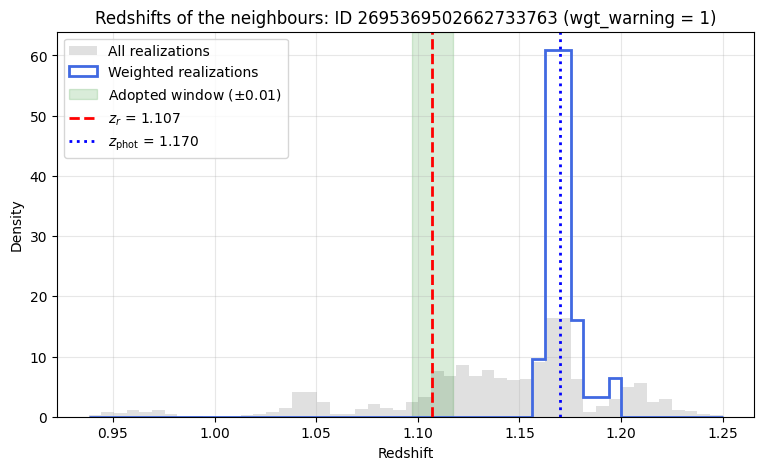

--- Example: failure (wgt_warning = 2) ---
⚠️ Object 2695202456662993133 has wgt_warning = 2: no valid realization within the maximum window.


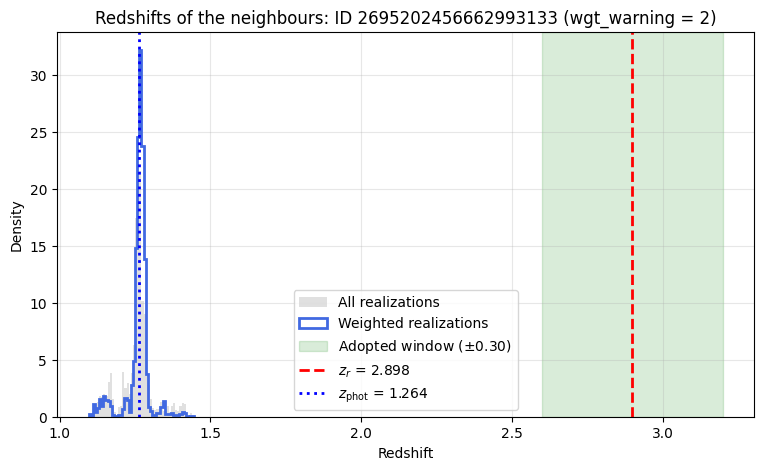

In [17]:
index_df, pp = load_reference_sample(euclid_survey=SURVEY)

example_ids = {
    'clean (wgt_warning = 0)':      pick_example(merged_catalog, 0, min_valid=50),
    'low weight (wgt_warning = 1)': pick_example(merged_catalog, 1),
    'failure (wgt_warning = 2)':    pick_example(merged_catalog, 2),
}

for label, obj_id in example_ids.items():
    print(f"--- Example: {label} ---")
    if obj_id is None:
        print("No object in this category.")
    else:
        plot_neighbor_redshifts(obj_id, merged_catalog, index_df, pp, zr_col='spe_z')

### 6.4 Corner plots of the physical properties

The corner plots show the joint distributions of the PPs from the realizations of the 30 neighbours, weighted by their NNPZ weights, together with the catalogue median (red square) and the new median at zr (green star).

* With `window_only=False`, **all** the realizations are shown: this is the redshift-marginalised distribution from which the catalogue values were derived.
* With `window_only=True`, only the realizations within the adopted window around zr and with positive weight are shown: these are the ones from which the new values were computed.

New medians are available for the parameters passed to `run_nnpz_evaluation`, and catalogue medians for those retrieved in the query.

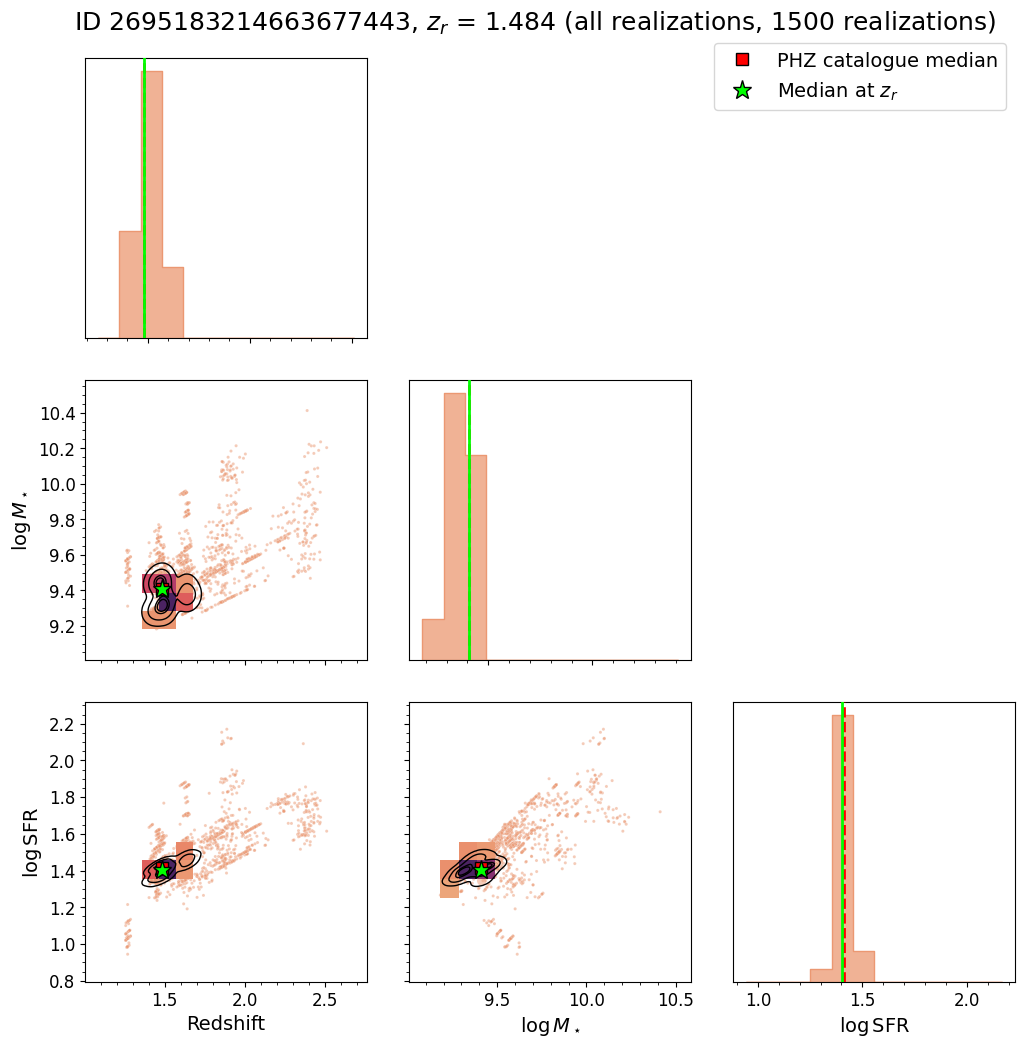

In [18]:
obj_id = example_ids['clean (wgt_warning = 0)']   # or any object_id of merged_catalog

corner_for_object(obj_id, merged_catalog, ['REDSHIFT', 'STELLARMASS', 'SFR'], index_df, pp,
                  zr_col='spe_z', window_only=False)

The same object, showing only the realizations used for the values at zr, with more parameters:

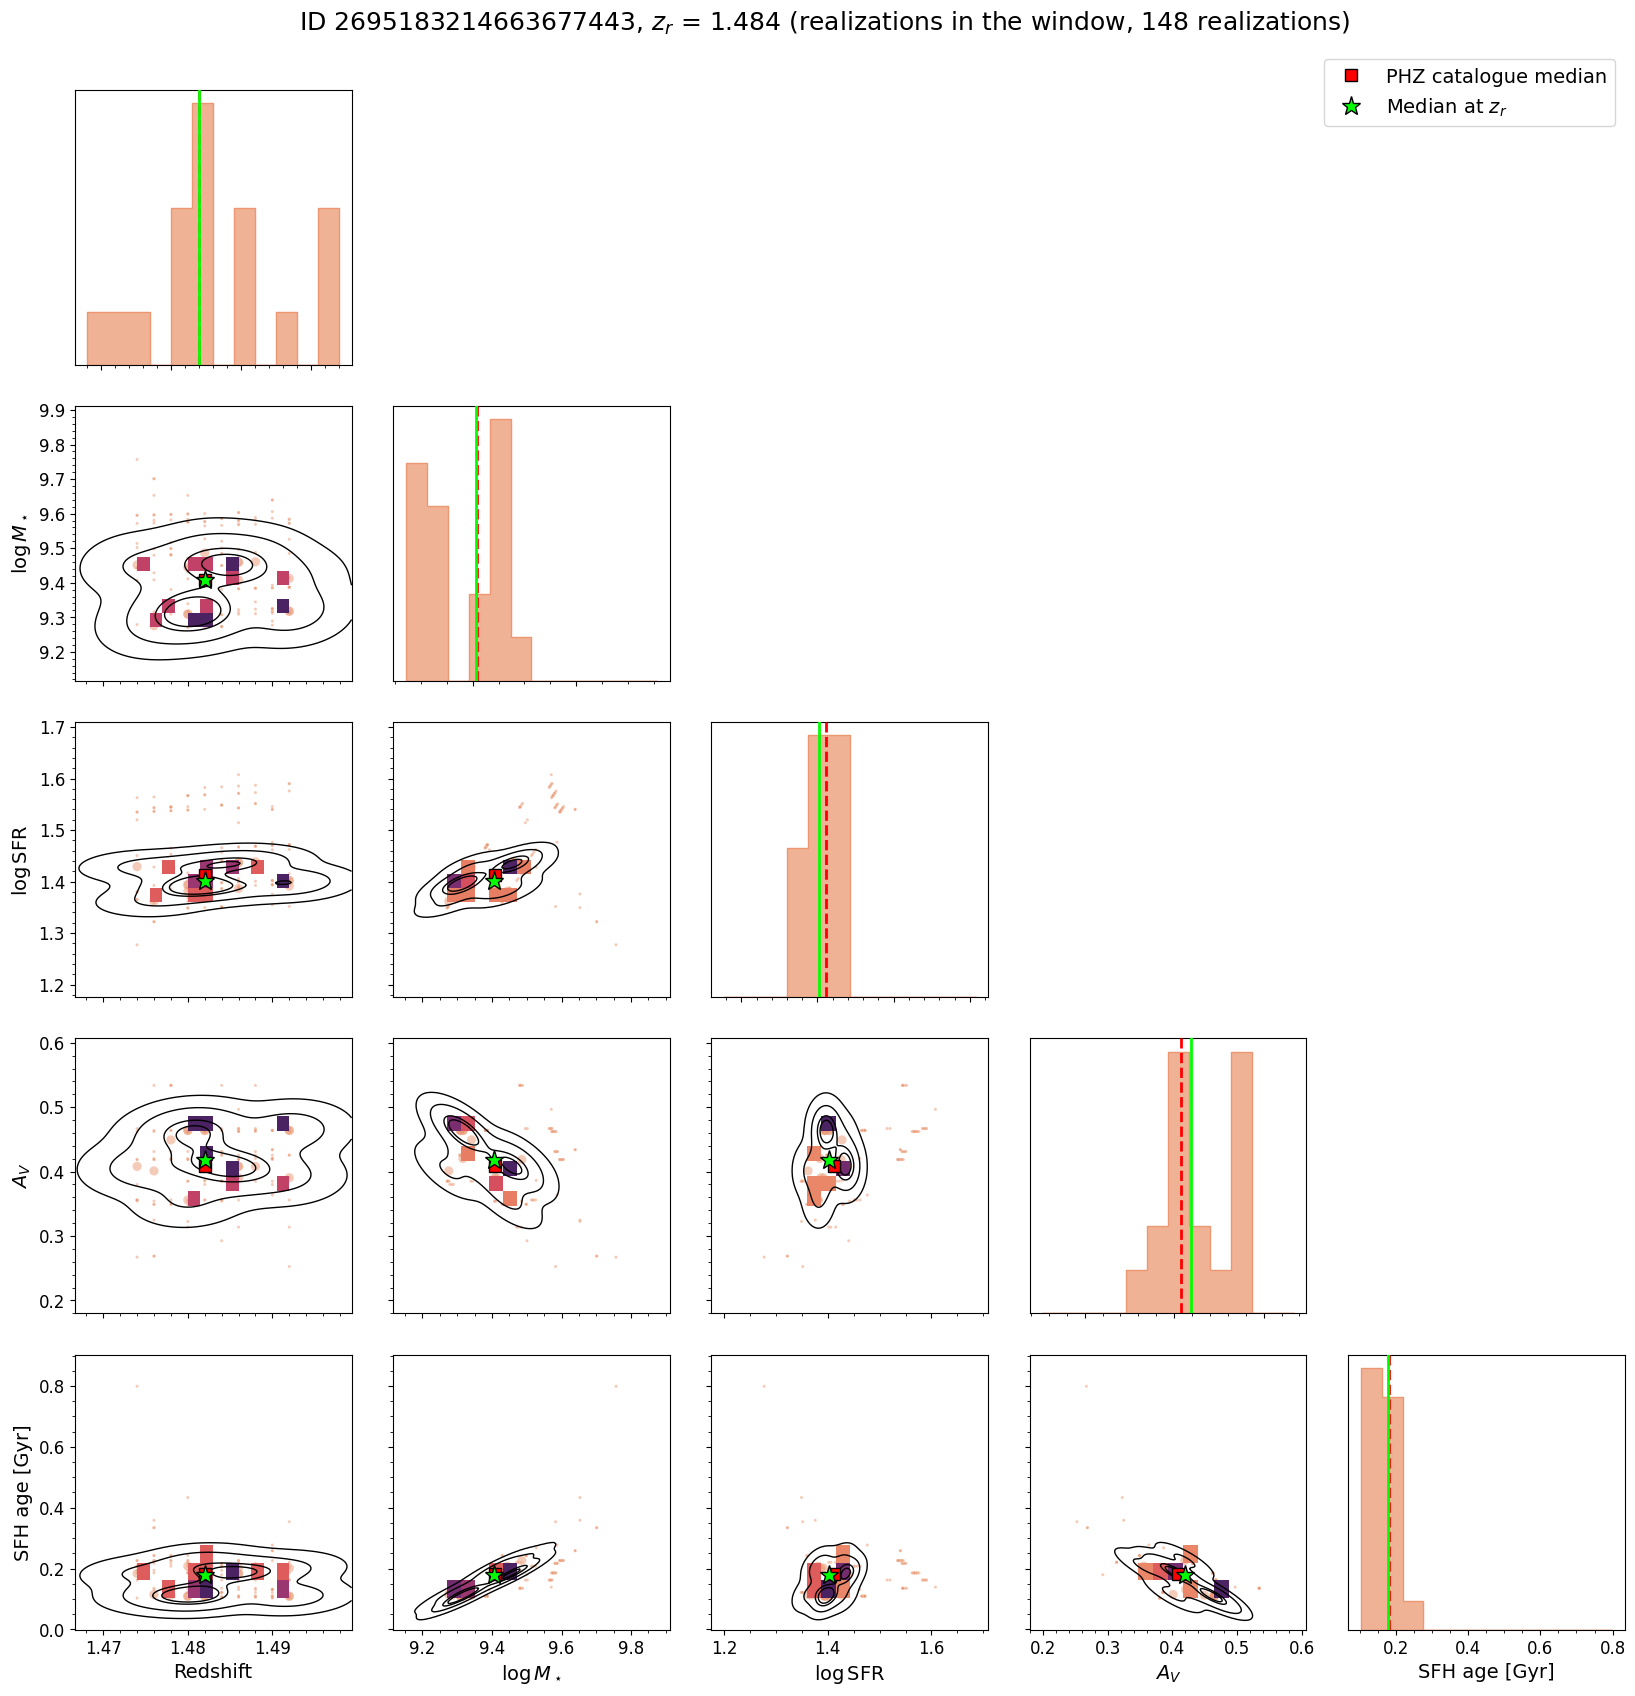

In [19]:
corner_for_object(obj_id, merged_catalog, ['REDSHIFT', 'STELLARMASS', 'SFR', 'AV', 'SFHAGE'], index_df, pp,
                  zr_col='spe_z', window_only=True)

An object with `wgt_warning = 1`, showing all its realizations:

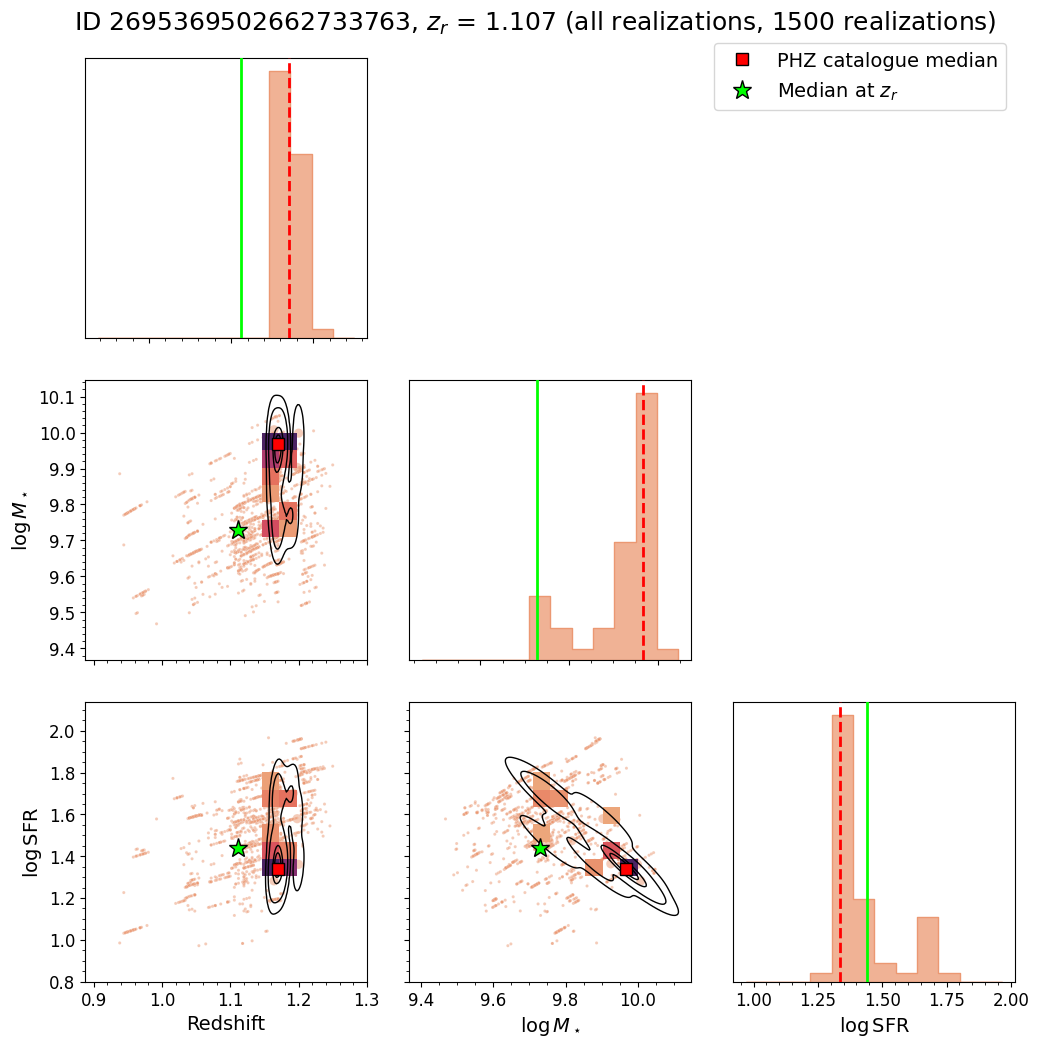

In [20]:
obj_id_low = example_ids['low weight (wgt_warning = 1)']   # or any object_id of merged_catalog

if obj_id_low is not None:
    corner_for_object(obj_id_low, merged_catalog, ['REDSHIFT', 'STELLARMASS', 'SFR'], index_df, pp,
                      zr_col='spe_z', window_only=False)

## Next steps

* To apply the method to your own redshifts, replace `spe_results_table` in Section 5 with any table containing `object_id` and a redshift column, and set `zr_col` accordingly.
* The companion notebook `PP_at_z_companion.ipynb` shows how to retrieve the PHZ catalogue for any list of objects, uploading it to the archive; it also compares the SPE redshifts with the PHZ photometric redshifts.